# 03 — Métricas de la Línea Base (Fase 1)

Evaluación cuantitativa del pipeline baseline: calidad del tracking, plausibilidad cinemática, suavidad de trayectoria y costo computacional.

**Archivos de entrada:**
- `baseline_distances.csv` — distancia acumulada por track ID (siempre disponible)
- `baseline_frame_data.csv` — datos por frame (requiere re-ejecutar `baseline_tracker.py`)
- `baseline_timing.json` — métricas de tiempo y memoria (requiere re-ejecutar `baseline_tracker.py`)

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
BASE_DIR = Path('..') / 'data' / 'processed'
EXPECTED_PLAYERS = 22

# --- Carga de datos ---
distances_df = pd.read_csv(BASE_DIR / 'baseline_distances.csv')
print(f'Distancias cargadas: {len(distances_df)} track IDs')

frame_path = BASE_DIR / 'baseline_frame_data.csv'
timing_path = BASE_DIR / 'baseline_timing.json'

frame_df = pd.read_csv(frame_path) if frame_path.exists() else None
timing = json.loads(timing_path.read_text()) if timing_path.exists() else None

if frame_df is not None:
    print(f'Datos por frame: {len(frame_df)} registros')
else:
    print('⚠ Datos por frame no disponibles. Re-ejecute: python src/models/baseline_tracker.py')

if timing is not None:
    video_fps = timing['video_fps']
    print(f'Timing cargado — Video: {timing["video_resolution"]} @ {video_fps} FPS')
else:
    video_fps = 30.0
    print(f'⚠ Timing no disponible. Usando FPS por defecto: {video_fps}')

Distancias cargadas: 470 track IDs
Datos por frame: 7588 registros
Timing cargado — Video: 1548x898 @ 15.970614070110996 FPS


## 1. Calidad del Tracking

| Métrica | Qué mide |
|---|---|
| IDs únicos | Fragmentación (esperado ~22) |
| Tracks fantasma | IDs con vida muy corta |
| Longitud de tracks | Persistencia del tracker |

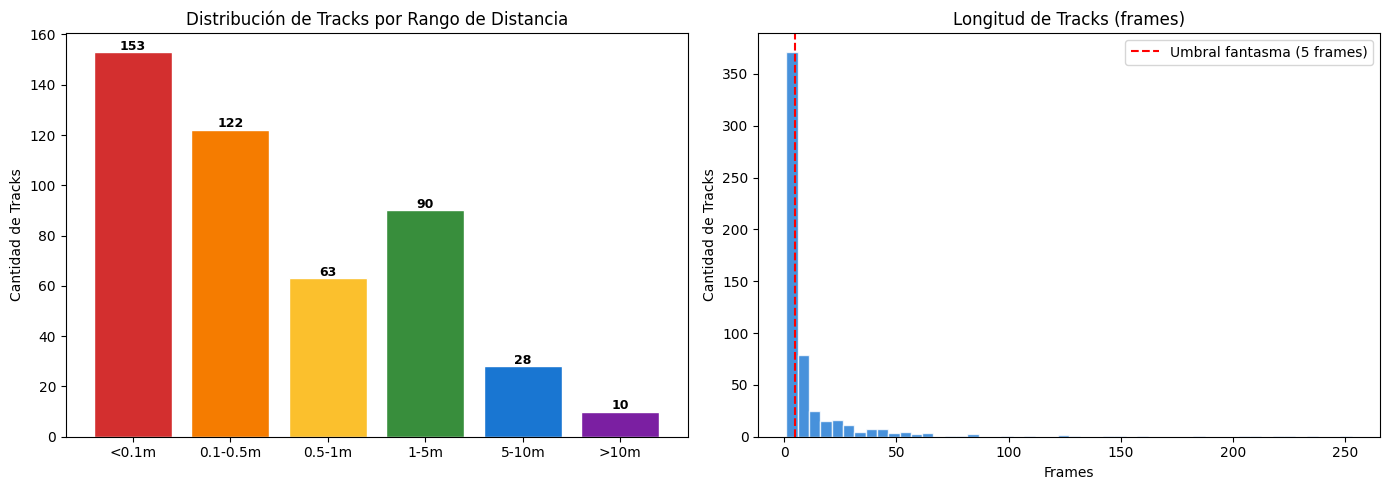

Track IDs únicos:        470
Jugadores esperados:     ~22
Ratio de fragmentación:  21.4x
Tracks fantasma (<0.1m): 153 (32.6%)
Tracks fantasma (<5 fr): 326 (69.4%)
Longitud promedio:       13.3 frames
Longitud mediana:        4 frames


In [2]:
n_ids = len(distances_df)
distances = distances_df['Distancia_Metros']

# Distribución por rangos de distancia
bins_dist = [0, 0.1, 0.5, 1.0, 5.0, 10.0, float('inf')]
labels_dist = ['<0.1m', '0.1-0.5m', '0.5-1m', '1-5m', '5-10m', '>10m']
distances_df['rango'] = pd.cut(distances, bins=bins_dist, labels=labels_dist)
dist_counts = distances_df['rango'].value_counts().reindex(labels_dist).fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors_bar = ['#d32f2f', '#f57c00', '#fbc02d', '#388e3c', '#1976d2', '#7b1fa2']
axes[0].bar(labels_dist, dist_counts.values, color=colors_bar, edgecolor='white')
axes[0].set_title('Distribución de Tracks por Rango de Distancia')
axes[0].set_ylabel('Cantidad de Tracks')
for i, v in enumerate(dist_counts.values):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold', fontsize=9)

if frame_df is not None:
    track_lengths = frame_df.groupby('track_id').size()
    axes[1].hist(track_lengths, bins=50, color='#1976d2', edgecolor='white', alpha=0.8)
    axes[1].axvline(x=5, color='red', linestyle='--', label='Umbral fantasma (5 frames)')
    axes[1].set_title('Longitud de Tracks (frames)')
    axes[1].set_xlabel('Frames')
    axes[1].set_ylabel('Cantidad de Tracks')
    axes[1].legend()
else:
    axes[1].text(0.5, 0.5, 'Requiere baseline_frame_data.csv',
                 transform=axes[1].transAxes, ha='center', va='center', fontsize=12, color='gray')
    axes[1].set_title('Longitud de Tracks (frames)')

plt.tight_layout()
plt.show()

n_ghost_dist = int(dist_counts.iloc[0])
print(f'Track IDs únicos:        {n_ids}')
print(f'Jugadores esperados:     ~{EXPECTED_PLAYERS}')
print(f'Ratio de fragmentación:  {n_ids / EXPECTED_PLAYERS:.1f}x')
print(f'Tracks fantasma (<0.1m): {n_ghost_dist} ({100 * n_ghost_dist / n_ids:.1f}%)')
if frame_df is not None:
    n_short = int((track_lengths < 5).sum())
    print(f'Tracks fantasma (<5 fr): {n_short} ({100 * n_short / n_ids:.1f}%)')
    print(f'Longitud promedio:       {track_lengths.mean():.1f} frames')
    print(f'Longitud mediana:        {track_lengths.median():.0f} frames')

## 2. ID Switches Estimados

Proxy de estabilidad: cada ID nuevo que aparece después del inicio se interpreta como un switch (pérdida y reasignación de identidad).

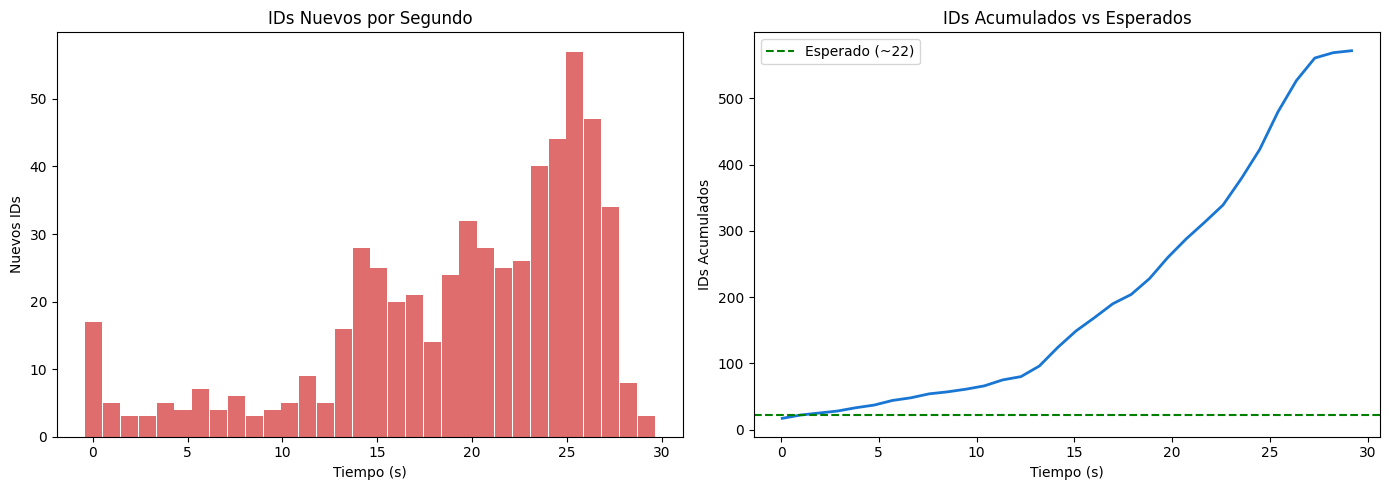

ID switches estimados:     ~448
Duración del video:        30.1 s
Tasa de switches:          14.91 switches/s


In [3]:
if frame_df is not None:
    window_frames = int(video_fps)
    max_frame = int(frame_df['frame'].max())

    windows = list(range(1, max_frame + 1, window_frames))
    new_ids_per_window = []
    seen_ids = set()

    for w_start in windows:
        w_end = w_start + window_frames
        window_ids = set(frame_df[(frame_df['frame'] >= w_start) & (frame_df['frame'] < w_end)]['track_id'])
        new_ids = window_ids - seen_ids
        new_ids_per_window.append(len(new_ids))
        seen_ids |= window_ids

    time_axis = [w / video_fps for w in windows]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].bar(time_axis, new_ids_per_window, width=0.9, color='#d32f2f', alpha=0.7)
    axes[0].set_title('IDs Nuevos por Segundo')
    axes[0].set_xlabel('Tiempo (s)')
    axes[0].set_ylabel('Nuevos IDs')

    cumulative_ids = np.cumsum(new_ids_per_window)
    axes[1].plot(time_axis, cumulative_ids, color='#1976d2', linewidth=2)
    axes[1].axhline(y=EXPECTED_PLAYERS, color='green', linestyle='--', label=f'Esperado (~{EXPECTED_PLAYERS})')
    axes[1].set_title('IDs Acumulados vs Esperados')
    axes[1].set_xlabel('Tiempo (s)')
    axes[1].set_ylabel('IDs Acumulados')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    total_switches = n_ids - EXPECTED_PLAYERS
    duration_s = max_frame / video_fps
    print(f'ID switches estimados:     ~{total_switches}')
    print(f'Duración del video:        {duration_s:.1f} s')
    print(f'Tasa de switches:          {total_switches / duration_s:.2f} switches/s')
else:
    total_switches = n_ids - EXPECTED_PLAYERS
    print(f'ID switches estimados (por distancia): ~{total_switches}')
    print('⚠ Gráficos temporales requieren baseline_frame_data.csv')

## 3. Plausibilidad Cinemática — Velocidades

La física como ground truth: velocidades >12 m/s son imposibles para un ser humano en fútbol.

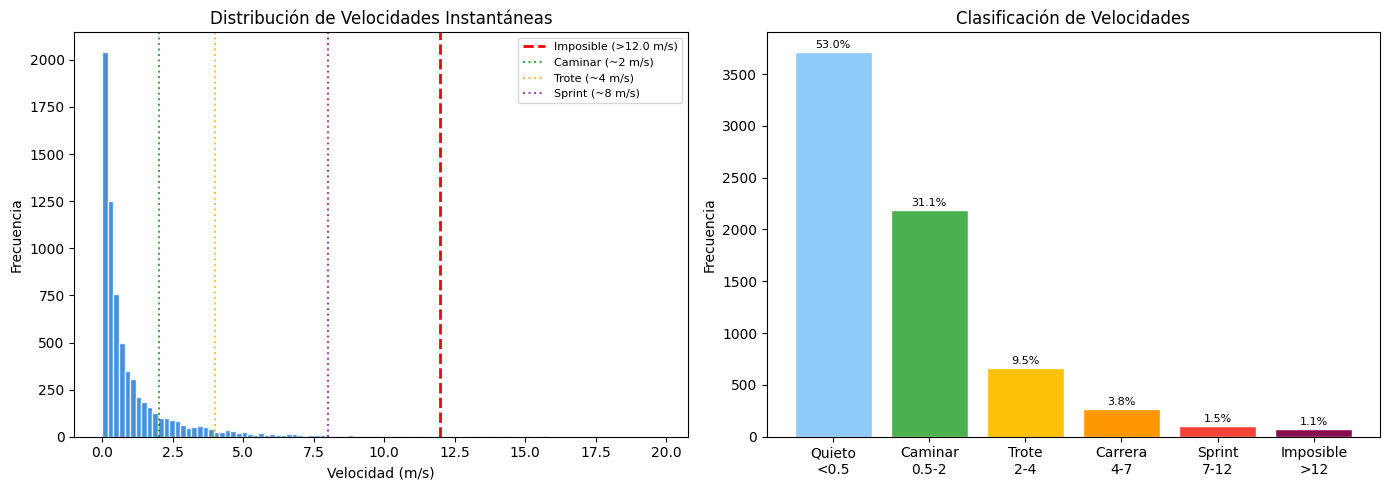

Velocidad media:              1.47 m/s
Velocidad mediana:            0.44 m/s
Velocidad máxima:             205.19 m/s
% velocidades imposibles:     1.1% (>12.0 m/s)


In [4]:
if frame_df is not None:
    speeds = frame_df.loc[frame_df['dist_meters'] > 0, 'dist_meters'] * video_fps

    IMPOSSIBLE_THRESHOLD = 12.0
    n_impossible = int((speeds > IMPOSSIBLE_THRESHOLD).sum())
    pct_impossible = 100 * n_impossible / len(speeds)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].hist(speeds[speeds <= 20], bins=100, color='#1976d2', edgecolor='white', alpha=0.8)
    axes[0].axvline(x=IMPOSSIBLE_THRESHOLD, color='red', linestyle='--', lw=2, label=f'Imposible (>{IMPOSSIBLE_THRESHOLD} m/s)')
    axes[0].axvline(x=2, color='green', linestyle=':', alpha=0.7, label='Caminar (~2 m/s)')
    axes[0].axvline(x=4, color='orange', linestyle=':', alpha=0.7, label='Trote (~4 m/s)')
    axes[0].axvline(x=8, color='purple', linestyle=':', alpha=0.7, label='Sprint (~8 m/s)')
    axes[0].set_title('Distribución de Velocidades Instantáneas')
    axes[0].set_xlabel('Velocidad (m/s)')
    axes[0].set_ylabel('Frecuencia')
    axes[0].legend(fontsize=8)

    speed_labels = ['Quieto\n<0.5', 'Caminar\n0.5-2', 'Trote\n2-4', 'Carrera\n4-7', 'Sprint\n7-12', 'Imposible\n>12']
    speed_bins = [0, 0.5, 2, 4, 7, 12, float('inf')]
    speed_cats = pd.cut(speeds, bins=speed_bins, labels=speed_labels)
    speed_counts = speed_cats.value_counts().reindex(speed_labels).fillna(0)
    colors_spd = ['#90caf9', '#4caf50', '#ffc107', '#ff9800', '#f44336', '#880e4f']
    axes[1].bar(speed_labels, speed_counts.values, color=colors_spd, edgecolor='white')
    axes[1].set_title('Clasificación de Velocidades')
    axes[1].set_ylabel('Frecuencia')
    for i, v in enumerate(speed_counts.values):
        if v > 0:
            axes[1].text(i, v + max(speed_counts) * 0.01, f'{100 * v / len(speeds):.1f}%',
                         ha='center', fontsize=8)

    plt.tight_layout()
    plt.show()

    print(f'Velocidad media:              {speeds.mean():.2f} m/s')
    print(f'Velocidad mediana:            {speeds.median():.2f} m/s')
    print(f'Velocidad máxima:             {speeds.max():.2f} m/s')
    print(f'% velocidades imposibles:     {pct_impossible:.1f}% (>{IMPOSSIBLE_THRESHOLD} m/s)')
else:
    pct_impossible = None
    speeds = None
    print('⚠ Requiere baseline_frame_data.csv')

## 4. Distribución de Distancias

Comparación con la literatura: un jugador de fútbol recorre 8–13 km en 90 minutos.

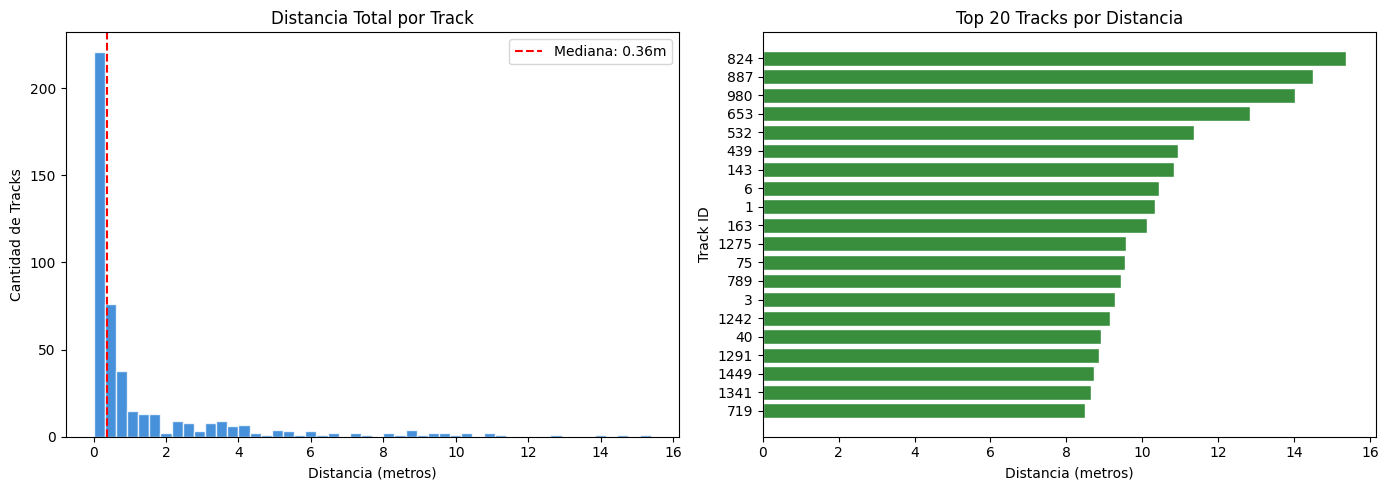

Distancia total (todos los tracks): 644.0 m
Distancia promedio por ID:          1.37 m
Distancia máxima (1 track):         15.38 m
Distancia estimada por jugador:     29.3 m

Duración del video:                 0.5 min
Extrapolación a 90 min/jugador:     5.3 km
Rango esperado (literatura):        8–13 km


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(distances, bins=50, color='#1976d2', edgecolor='white', alpha=0.8)
axes[0].axvline(x=distances.median(), color='red', linestyle='--',
                label=f'Mediana: {distances.median():.2f}m')
axes[0].set_title('Distancia Total por Track')
axes[0].set_xlabel('Distancia (metros)')
axes[0].set_ylabel('Cantidad de Tracks')
axes[0].legend()

top_n = 20
top_tracks = distances_df.nlargest(top_n, 'Distancia_Metros')
axes[1].barh(top_tracks['Track_ID'].astype(str), top_tracks['Distancia_Metros'],
             color='#388e3c', edgecolor='white')
axes[1].set_title(f'Top {top_n} Tracks por Distancia')
axes[1].set_xlabel('Distancia (metros)')
axes[1].set_ylabel('Track ID')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

total_dist = float(distances.sum())
print(f'Distancia total (todos los tracks): {total_dist:.1f} m')
print(f'Distancia promedio por ID:          {distances.mean():.2f} m')
print(f'Distancia máxima (1 track):         {distances.max():.2f} m')
print(f'Distancia estimada por jugador:     {total_dist / EXPECTED_PLAYERS:.1f} m')

if timing:
    duration_min = timing['total_frames'] / video_fps / 60
    km_90min = (total_dist / EXPECTED_PLAYERS) / duration_min * 90 / 1000
    print(f'\nDuración del video:                 {duration_min:.1f} min')
    print(f'Extrapolación a 90 min/jugador:     {km_90min:.1f} km')
    print(f'Rango esperado (literatura):        8–13 km')

## 5. Suavidad de Trayectoria

- **Varianza de aceleración**: cuánto cambia la velocidad entre frames consecutivos (alto = ruidoso).
- **Ratio cruda/filtrada**: cuánta distancia es atribuible a jitter (ruido de detección).

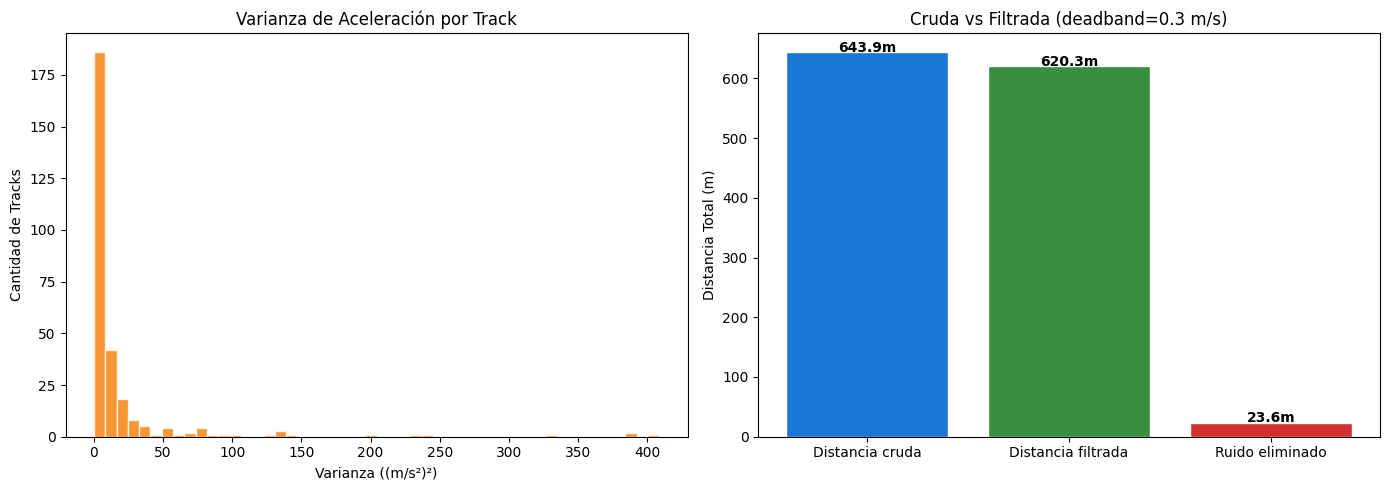

Varianza media de aceleración: 159.4108 (m/s²)²
Distancia cruda total:         643.9 m
Distancia filtrada total:      620.3 m
Ratio cruda/filtrada:          1.04
% ruido (jitter):              3.7%


In [6]:
if frame_df is not None:
    frame_speeds = frame_df.loc[frame_df['dist_meters'] > 0].copy()
    frame_speeds['speed'] = frame_speeds['dist_meters'] * video_fps

    accel_variances = []
    for _, group in frame_speeds.groupby('track_id'):
        if len(group) > 2:
            accels = group['speed'].diff().dropna()
            accel_variances.append(accels.var())
    accel_variances = np.array(accel_variances)

    DEADBAND = 0.3  # m/s
    raw_total = float(frame_speeds['dist_meters'].sum())
    filtered_total = float(frame_speeds.loc[frame_speeds['speed'] >= DEADBAND, 'dist_meters'].sum())
    raw_filt_ratio = raw_total / filtered_total if filtered_total > 0 else float('inf')
    noise_pct = 100 * (1 - filtered_total / raw_total) if raw_total > 0 else 0

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    p95 = np.percentile(accel_variances, 95)
    axes[0].hist(accel_variances[accel_variances < p95], bins=50,
                 color='#f57c00', edgecolor='white', alpha=0.8)
    axes[0].set_title('Varianza de Aceleración por Track')
    axes[0].set_xlabel('Varianza ((m/s²)²)')
    axes[0].set_ylabel('Cantidad de Tracks')

    bar_labels = ['Distancia cruda', 'Distancia filtrada', 'Ruido eliminado']
    bar_values = [raw_total, filtered_total, raw_total - filtered_total]
    bar_colors = ['#1976d2', '#388e3c', '#d32f2f']
    axes[1].bar(bar_labels, bar_values, color=bar_colors, edgecolor='white')
    axes[1].set_title(f'Cruda vs Filtrada (deadband={DEADBAND} m/s)')
    axes[1].set_ylabel('Distancia Total (m)')
    for i, v in enumerate(bar_values):
        axes[1].text(i, v + 0.5, f'{v:.1f}m', ha='center', fontweight='bold')

    plt.tight_layout()
    plt.show()

    mean_accel_var = float(accel_variances.mean())
    print(f'Varianza media de aceleración: {mean_accel_var:.4f} (m/s²)²')
    print(f'Distancia cruda total:         {raw_total:.1f} m')
    print(f'Distancia filtrada total:      {filtered_total:.1f} m')
    print(f'Ratio cruda/filtrada:          {raw_filt_ratio:.2f}')
    print(f'% ruido (jitter):              {noise_pct:.1f}%')
else:
    mean_accel_var = None
    raw_total = None
    filtered_total = None
    raw_filt_ratio = None
    noise_pct = None
    print('⚠ Requiere baseline_frame_data.csv')

## 6. Costo Computacional

In [7]:
if timing:
    print(f'{"="*50}')
    print(f'COSTO COMPUTACIONAL')
    print(f'{"="*50}')
    print(f'Tiempo total:         {timing["total_time_s"]:.1f} s ({timing["total_time_s"] / 60:.1f} min)')
    print(f'Frames procesados:    {timing["total_frames"]}')
    print(f'FPS de procesamiento: {timing["fps_processing"]:.1f}')
    print(f'Tiempo por frame:     {timing["avg_frame_ms"]:.1f} ms')
    print(f'Uso pico de RAM:      {timing["peak_ram_mb"]:.1f} MB')
    print(f'Uso pico de VRAM:     {timing["peak_vram_mb"]:.1f} MB')
    print(f'Resolución del video: {timing["video_resolution"]}')
    print(f'FPS del video:        {timing["video_fps"]}')
else:
    print('⚠ Requiere baseline_timing.json')

COSTO COMPUTACIONAL
Tiempo total:         120.0 s (2.0 min)
Frames procesados:    480
FPS de procesamiento: 4.0
Tiempo por frame:     243.5 ms
Uso pico de RAM:      83.8 MB
Uso pico de VRAM:     0.0 MB
Resolución del video: 1548x898
FPS del video:        15.970614070110996


## 7. Tabla Resumen — Línea Base

Exporta todas las métricas a `baseline_metrics.json` para comparación con Fase 2.

In [8]:
metrics = {
    'phase': 'baseline',
    'tracking': {
        'n_unique_ids': n_ids,
        'expected_players': EXPECTED_PLAYERS,
        'fragmentation_ratio': round(n_ids / EXPECTED_PLAYERS, 1),
        'n_ghost_tracks_by_dist': n_ghost_dist,
        'pct_ghost_tracks_by_dist': round(100 * n_ghost_dist / n_ids, 1),
        'id_switches_estimated': n_ids - EXPECTED_PLAYERS,
    },
    'distances': {
        'total_m': round(total_dist, 1),
        'mean_per_id_m': round(float(distances.mean()), 2),
        'median_per_id_m': round(float(distances.median()), 2),
        'max_m': round(float(distances.max()), 2),
        'estimated_per_player_m': round(total_dist / EXPECTED_PLAYERS, 1),
    },
}

if frame_df is not None:
    metrics['tracking']['n_ghost_tracks_by_frames'] = n_short
    metrics['tracking']['avg_track_length_frames'] = round(float(track_lengths.mean()), 1)
    metrics['tracking']['median_track_length_frames'] = round(float(track_lengths.median()), 0)

if speeds is not None:
    metrics['kinematics'] = {
        'mean_speed_ms': round(float(speeds.mean()), 2),
        'median_speed_ms': round(float(speeds.median()), 2),
        'max_speed_ms': round(float(speeds.max()), 2),
        'pct_impossible_speed': round(pct_impossible, 1),
    }

if mean_accel_var is not None:
    metrics['smoothness'] = {
        'mean_accel_variance': round(mean_accel_var, 4),
        'raw_distance_m': round(raw_total, 1),
        'filtered_distance_m': round(filtered_total, 1),
        'raw_filtered_ratio': round(raw_filt_ratio, 2),
        'noise_pct': round(noise_pct, 1),
    }

if timing:
    metrics['computational_cost'] = {
        'total_time_s': timing['total_time_s'],
        'total_frames': timing['total_frames'],
        'fps_processing': timing['fps_processing'],
        'avg_frame_ms': timing['avg_frame_ms'],
        'peak_ram_mb': timing['peak_ram_mb'],
        'peak_vram_mb': timing['peak_vram_mb'],
        'video_fps': timing['video_fps'],
    }

output_path = BASE_DIR / 'baseline_metrics.json'
with open(output_path, 'w') as f:
    json.dump(metrics, f, indent=2)

print(f'Métricas exportadas a: {output_path}\n')
print(f'{"="*60}')
print(f'RESUMEN — LÍNEA BASE (Fase 1)')
print(f'{"="*60}')
for category, values in metrics.items():
    if isinstance(values, dict):
        print(f'\n  {category.upper()}:')
        for k, v in values.items():
            print(f'    {k:.<40} {v}')
    else:
        print(f'  {category}: {values}')

Métricas exportadas a: ..\data\processed\baseline_metrics.json

RESUMEN — LÍNEA BASE (Fase 1)
  phase: baseline

  TRACKING:
    n_unique_ids............................ 470
    expected_players........................ 22
    fragmentation_ratio..................... 21.4
    n_ghost_tracks_by_dist.................. 153
    pct_ghost_tracks_by_dist................ 32.6
    id_switches_estimated................... 448
    n_ghost_tracks_by_frames................ 326
    avg_track_length_frames................. 13.3
    median_track_length_frames.............. 4.0

  DISTANCES:
    total_m................................. 644.0
    mean_per_id_m........................... 1.37
    median_per_id_m......................... 0.36
    max_m................................... 15.38
    estimated_per_player_m.................. 29.3

  KINEMATICS:
    mean_speed_ms........................... 1.47
    median_speed_ms......................... 0.44
    max_speed_ms............................ 205.19